In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy
from scipy.stats import ttest_ind
import seaborn as sns
from math import sqrt
import re
from matplotlib.ticker import ScalarFormatter
import matplotlib.ticker as mticker
from itertools import product

cell_types = ["Exc", "Pvalb", "Sst", "Vip", "Htr3a"]
layers = ["L1", "L2/3", "L4", "L5", "L6"]
colors = [
    "tab:red",
    "tab:blue",
    "tab:green",
    "tab:purple",
    "tab:purple",
]

In [2]:
net_name = "core"  # change to "core_<variant>" for a model variant
power_layers = pd.read_csv(f"{net_name}/metrics/gray_screen_vs_dg_power/dg_all_dirs_mua_power_layer.csv")
power_pop_name = pd.read_csv(f"{net_name}/metrics/gray_screen_vs_dg_power/dg_all_dirs_mua_power.csv")

In [3]:
def str2list(str_time):
    str_time = str_time[1:-1]
    array_list = str_time.strip(",").split(", ")
    return np.stack([float(ii) for ii in array_list])

In [4]:
power_layers["power"] = power_layers["power"].apply(str2list)
power_layers["f"] = power_layers["f"].apply(str2list)

power_pop_name["power"] = power_pop_name["power"].apply(str2list)
power_pop_name["f"] = power_pop_name["f"].apply(str2list)

In [5]:
power_layers.condition.unique()

array(['drifting gratings', 'gray screen'], dtype=object)

In [6]:
power_layers_df = power_layers.groupby(["condition", "layer"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_layers_df.reset_index(inplace=True)
power_layers_df["mean"] = power_layers_df["power"].apply(np.mean, axis=0)
power_layers_df["std"] = power_layers_df["power"].apply(np.std, axis=0)
power_layers_df["se"] = power_layers_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_layers_df["f"] = power_layers_df["f"].apply(np.mean, axis=0)

In [7]:
power_pop_name_df = power_pop_name.groupby(["condition", "layer", "cell"]).agg(
    {
        "power": list,
        "f": list,
    }
)
power_pop_name_df.reset_index(inplace=True)
power_pop_name_df["mean"] = power_pop_name_df["power"].apply(np.mean, axis=0)
power_pop_name_df["std"] = power_pop_name_df["power"].apply(np.std, axis=0)
power_pop_name_df["se"] = power_pop_name_df["power"].apply(lambda x: np.std(x, axis=0) / np.sqrt(len(x)))
power_pop_name_df["f"] = power_pop_name_df["f"].apply(np.mean, axis=0)

## Fig1 - sponteneous activity - power spectrum

cell Exc layer_count L2/3    2
L4      2
L5      2
L6      2
Name: layer, dtype: int64
cell Pvalb layer_count L2/3    2
L4      2
L5      2
L6      2
Name: layer, dtype: int64
cell Sst layer_count L2/3    2
L4      2
L5      2
L6      2
Name: layer, dtype: int64


cell Vip layer_count L2/3    2
L4      2
L5      2
L6      2
Name: layer, dtype: int64


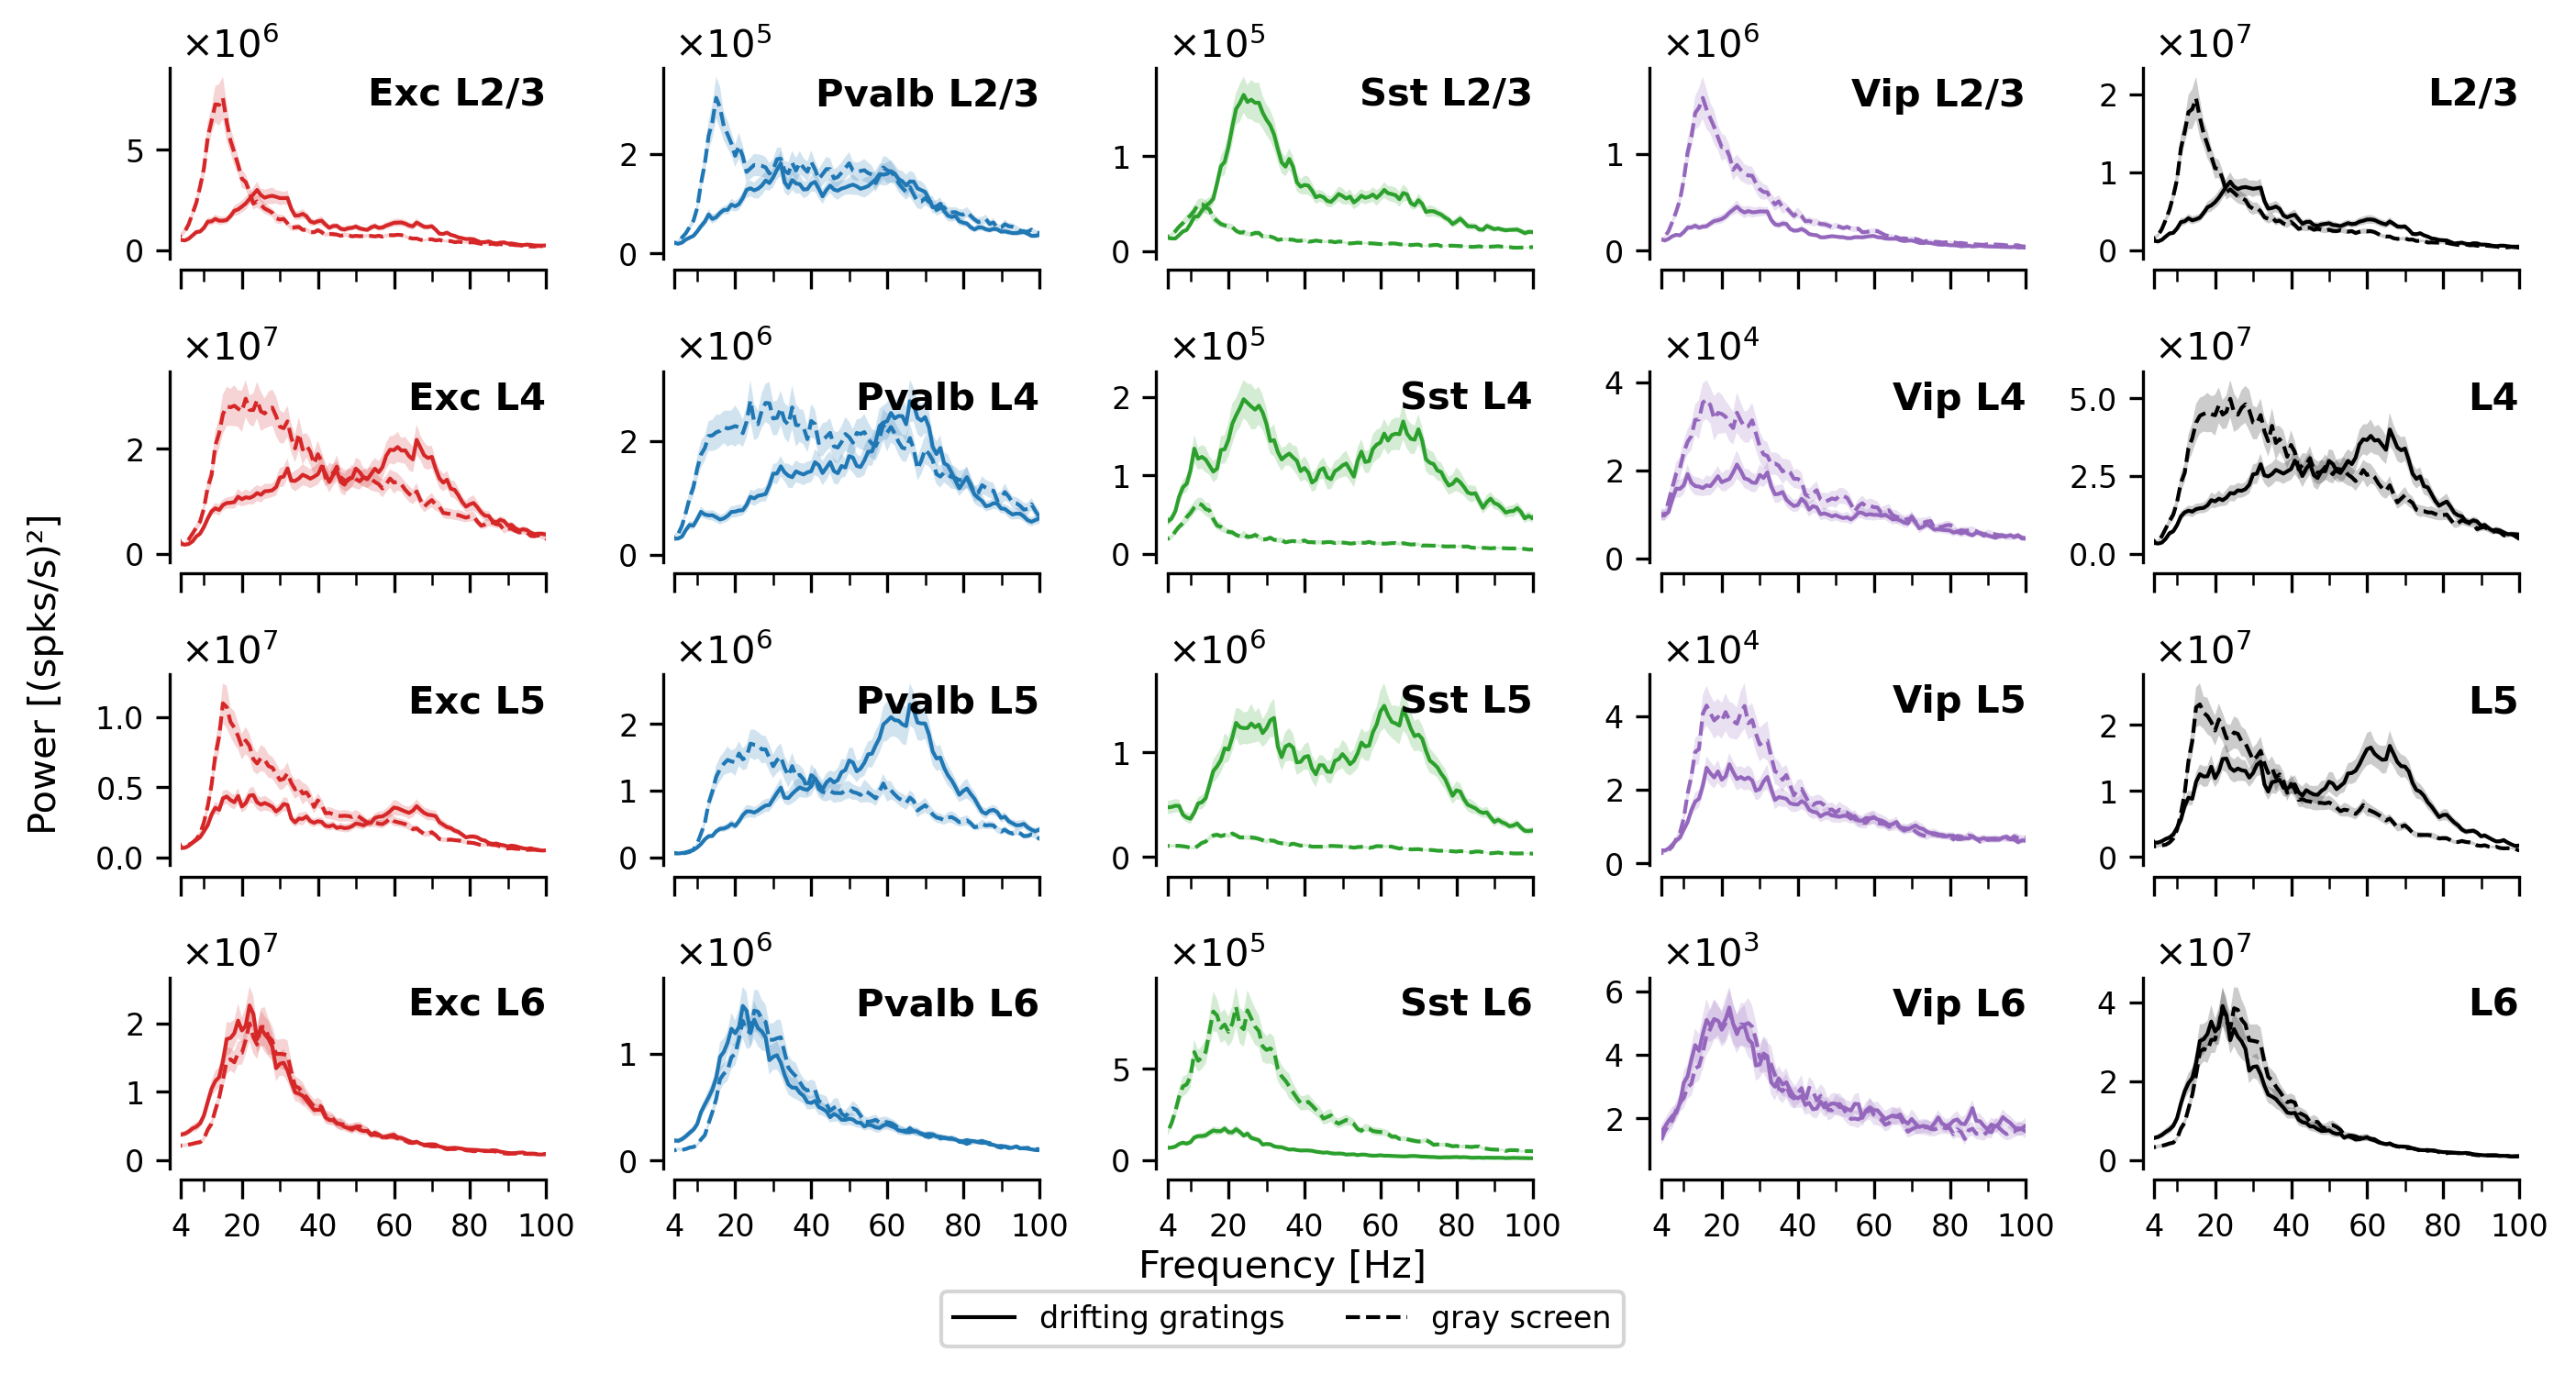

In [8]:
selected_cells = ["Exc", "Pvalb", "Sst", "Vip"]
conditions = ["drifting gratings", "gray screen"]
condition_linestyles = {"drifting gratings": "-", "gray screen": "--"}

fig, axes = plt.subplots(ncols=5, nrows=4, sharex=True, figsize=(9.5, 5), dpi=300)
fig.patch.set_facecolor("none")
f = power_pop_name_df.loc[0, "f"]
for (jj, cell), c in zip(enumerate(selected_cells), colors):
    data_all = power_pop_name_df.query('cell == "' + cell + '"')
    print("cell {} layer_count {}".format(cell, data_all.layer.value_counts()))

    for ii, layer in enumerate(layers[1:]):
        ax = axes[ii, jj]
        for condition in conditions:
            data = data_all.query('condition == "' + condition + '"')
            if len(data) == 0:
                continue
            data = data.reset_index(drop=True)
            m = data.loc[
                (data["layer"] == layer).values,
                "mean",
            ].values[0]
            s = data.loc[
                (data["layer"] == layer).values,
                "se",
            ].values[0]

            ax.plot(
                f[1:],
                m[1:],
                color=c,
                linewidth=1,
                linestyle=condition_linestyles[condition],
                label=condition,
            )
            ax.fill_between(
                f[1:],
                m[1:] - 1.96 * s[1:],
                m[1:] + 1.96 * s[1:],
                facecolor=c,
                alpha=0.2,
            )

        sns.despine()
        ax.spines["left"].set_position(("outward", 3))
        ax.spines["bottom"].set_position(("outward", 3))

        ax.set_xlim([4, 100])

        ax.set_xticks([4, 20, 40, 60, 80, 100])
        ax.set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=8)
        ax.set_xticks([10, 30, 50, 70, 90], minor=True)
        ax.tick_params(axis='x', which='major', length=5)
        ax.tick_params(axis='x', which='minor', length=3)

        formatter = ScalarFormatter(useMathText=True)
        formatter.set_powerlimits((-3, 3))
        ax.yaxis.set_major_formatter(formatter)
        ax.ticklabel_format(axis="y", style="scientific", scilimits=(-3, 3))
        ax.tick_params(axis='y', labelsize=8)

        ax.text(
            1,
            0.95,
            cell + " " + layer,
            horizontalalignment="right",
            verticalalignment="top",
            fontsize=10,
            alpha=1,
            transform=ax.transAxes,
            fontweight="bold",
        )

jj += 1
for ii, layer in enumerate(layers[1:]):
    ax = axes[ii, jj]
    for condition in conditions:
        data = power_layers_df.query('condition == "' + condition + '"')
        if len(data) == 0:
            continue
        m = data.loc[
            (data["layer"] == layer).values,
            "mean",
        ].values[0]
        s = data.loc[
            (data["layer"] == layer).values,
            "se",
        ].values[0]
        ax.plot(
            f[1:],
            m[1:],
            color="k",
            linewidth=1,
            linestyle=condition_linestyles[condition],
            label=condition,
        )
        ax.fill_between(
            f[1:], m[1:] - 1.96 * s[1:], m[1:] + 1.96 * s[1:], facecolor="k", alpha=0.2
        )

    sns.despine()
    ax.spines["left"].set_position(("outward", 3))
    ax.spines["bottom"].set_position(("outward", 3))

    ax.set_xlim([4, 100])

    ax.set_xticks([4, 20, 40, 60, 80, 100])
    ax.set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=8)
    ax.set_xticks([10, 30, 50, 70, 90], minor=True)
    ax.tick_params(axis='x', which='major', length=5)
    ax.tick_params(axis='x', which='minor', length=3)

    formatter = ScalarFormatter(useMathText=True)
    formatter.set_powerlimits((-3, 2))
    ax.yaxis.set_major_formatter(formatter)
    ax.ticklabel_format(axis="y", style="scientific", scilimits=(-3, 2))
    ax.tick_params(axis='y', labelsize=8)

    ax.text(
        1,
        0.95,
        layer,
        horizontalalignment="right",
        verticalalignment="top",
        fontsize=10,
        alpha=1,
        transform=ax.transAxes,
        fontweight="bold",
    )

# Add legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color="k", linewidth=1, linestyle="-", label="drifting gratings"),
    Line2D([0], [0], color="k", linewidth=1, linestyle="--", label="gray screen"),
]
fig.legend(handles=legend_elements, loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, 0.0))

fig.supxlabel("Frequency [Hz]", fontsize=10, y=0.055)
fig.supylabel("Power [(spks/s)²]", fontsize=10)
fig.tight_layout()
fig.savefig(
    "paper_figs/fig1_suppl_gs_power_Jul27_2026.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)


In [9]:
mean_power_cond = power_layers_df.groupby(["condition"]).agg(
    {
        "mean": list,
    }
)
mean_power_cond["max"] = mean_power_cond["mean"].apply(
    lambda row: np.max(np.vstack(np.asanyarray(row)), axis=0)
)
mean_power_cond.rename(columns={"index": "condition"})
mean_power_cond.reset_index(inplace=True)


def get_norm_power(row):
    max_values = mean_power_cond.loc[
        mean_power_cond["condition"].isin([row["condition"]]).values,
        "max",
    ].values[0]
    # print(row["contrast"])
    norm_power = row["mean"] / max_values
    # print(np.max(norm_power))
    return norm_power


power_layers_df["norm power"] = power_layers_df.apply(
    lambda row: get_norm_power(row), axis=1
)

Drifting Gratings vs Gray Screen  —  SSIM=0.939  Pearson r=0.955


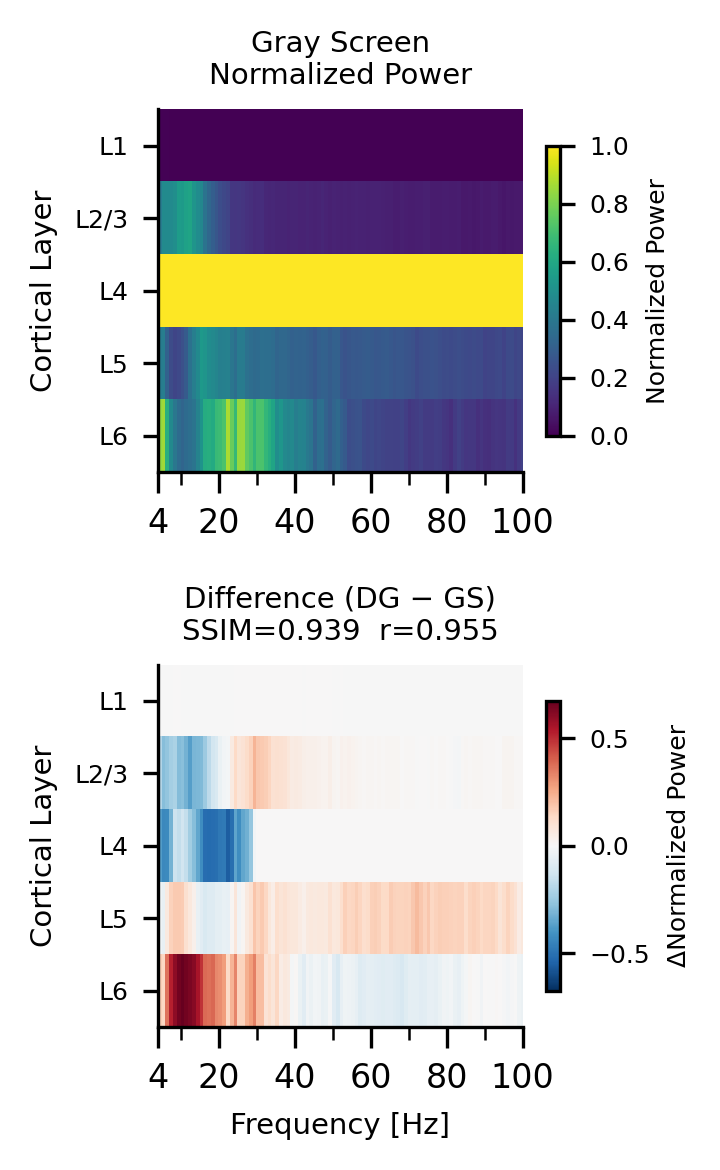

In [10]:

from skimage.metrics import structural_similarity as ssim
from scipy.stats import pearsonr

# Create laminar power colormap plots: normalized power per condition + difference
fig, axes = plt.subplots(ncols=1, nrows=2, figsize=(2.5, 4), dpi=300)
fig.patch.set_facecolor("white")

layers_all = layers  # ["L1", "L2/3", "L4", "L5", "L6"]
plot_conditions = ["drifting gratings", "gray screen"]
power_matrices_norm = {}

for condition in plot_conditions:
    data = power_layers_df.query('condition == "' + condition + '"')
    if len(data) == 0:
        continue

    f = data.loc[data.index[0], "f"]
    power_matrix = np.zeros((len(layers_all), len(f[1:])))

    for i, layer in enumerate(layers_all):
        layer_data = data[data["layer"] == layer]
        if len(layer_data) > 0:
            power_matrix[i, :] = layer_data["mean"].iloc[0][1:]

    # Normalize by maximum power per frequency across layers
    max_power_per_freq = np.max(power_matrix, axis=0)
    max_power_per_freq[max_power_per_freq == 0] = 1  # avoid division by zero
    power_matrices_norm[condition] = power_matrix / max_power_per_freq

# Compute SSIM and Pearson r between the two conditions
ref_img = power_matrices_norm["drifting gratings"]
cmp_img = power_matrices_norm["gray screen"]
ssim_val = ssim(ref_img, cmp_img, data_range=1.0, win_size=3)
r_val, _ = pearsonr(ref_img.flatten(), cmp_img.flatten())
print(f"Drifting Gratings vs Gray Screen  —  SSIM={ssim_val:.3f}  Pearson r={r_val:.3f}")

# # Panel 0: Normalized power - drifting gratings
# im0 = axes[0].imshow(
#     power_matrices_norm["drifting gratings"],
#     aspect="auto",
#     origin="upper",
#     extent=[f[1], f[-1], len(layers_all), 0],
#     cmap="viridis",
#     vmin=0,
#     vmax=1,
# )
# axes[0].set_title("Drifting Gratings\nNormalized Power", fontsize=7)
# axes[0].set_ylabel("Cortical Layer", fontsize=7)
# axes[0].set_yticks(np.arange(len(layers_all)) + 0.5)
# axes[0].set_yticklabels(layers_all, fontsize=6)
# axes[0].set_xlim([4, 100])
# axes[0].set_xticks([4, 20, 40, 60, 80, 100])
# axes[0].set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=8)
# axes[0].set_xticks([10, 30, 50, 70, 90], minor=True)
# axes[0].tick_params(axis='x', which='major', length=5)
# axes[0].tick_params(axis='x', which='minor', length=3)
# axes[0].spines["top"].set_visible(False)
# axes[0].spines["right"].set_visible(False)
# cbar0 = plt.colorbar(im0, ax=axes[0], shrink=0.8)
# cbar0.set_label("Normalized Power", fontsize=6)
# cbar0.ax.tick_params(labelsize=6)

# Panel 1: Normalized power - gray screen
im1 = axes[0].imshow(
    power_matrices_norm["gray screen"],
    aspect="auto",
    origin="upper",
    extent=[f[1], f[-1], len(layers_all), 0],
    cmap="viridis",
    vmin=0,
    vmax=1,
)
axes[0].set_title("Gray Screen\nNormalized Power", fontsize=7)
axes[0].set_ylabel("Cortical Layer", fontsize=7)
axes[0].set_yticks(np.arange(len(layers_all)) + 0.5)
axes[0].set_yticklabels(layers_all, fontsize=6)
axes[0].set_xlim([4, 100])
axes[0].set_xticks([4, 20, 40, 60, 80, 100])
axes[0].set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=8)
axes[0].set_xticks([10, 30, 50, 70, 90], minor=True)
axes[0].tick_params(axis='x', which='major', length=5)
axes[0].tick_params(axis='x', which='minor', length=3)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
cbar1 = plt.colorbar(im1, ax=axes[0], shrink=0.8)
cbar1.set_label("Normalized Power", fontsize=6)
cbar1.ax.tick_params(labelsize=6)

# Panel 2: Difference (drifting gratings - gray screen)
diff_matrix = power_matrices_norm["drifting gratings"] - power_matrices_norm["gray screen"]
abs_max = np.max(np.abs(diff_matrix))
im2 = axes[1].imshow(
    diff_matrix,
    aspect="auto",
    origin="upper",
    extent=[f[1], f[-1], len(layers_all), 0],
    cmap="RdBu_r",
    vmin=-abs_max,
    vmax=abs_max,
)
axes[1].set_title(f"Difference (DG − GS)\nSSIM={ssim_val:.3f}  r={r_val:.3f}", fontsize=7)
axes[1].set_xlabel("Frequency [Hz]", fontsize=7)
axes[1].set_ylabel("Cortical Layer", fontsize=7)
axes[1].set_yticks(np.arange(len(layers_all)) + 0.5)
axes[1].set_yticklabels(layers_all, fontsize=6)
axes[1].set_xlim([4, 100])
axes[1].set_xticks([4, 20, 40, 60, 80, 100])
axes[1].set_xticklabels([4, 20, 40, 60, 80, 100], fontsize=8)
axes[1].set_xticks([10, 30, 50, 70, 90], minor=True)
axes[1].tick_params(axis='x', which='major', length=5)
axes[1].tick_params(axis='x', which='minor', length=3)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
cbar2 = plt.colorbar(im2, ax=axes[1], shrink=0.8)
cbar2.set_label("ΔNormalized Power", fontsize=6)
cbar2.ax.tick_params(labelsize=6)

fig.tight_layout()
fig.savefig(
    "paper_figs/laminar_power_colormap_gs_vs_dg_Jul27_2026.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=False,
    facecolor="white",
)
